# Stork Flight: can an AI learn to fly from rewards alone?

**Part 2 of my reinforcement learning project.** In Part 1, an AI learned to land on the Moon (Gymnasium's Lunar Lander). Here I built my own environment from scratch: a stork flying between minarets and storm clouds over a Moroccan city.

The AI (PPO, from Stable-Baselines3) is never told what to do. It only gets rewards: **+0.1** for every step it stays alive, **+1** for each minaret it passes, **−1** when it crashes.

**Questions**
1. Does the AI beat a simple hand-written rule?
2. Does it get worse as the gaps get narrower and the game gets faster?
3. If it trains on one difficulty, can it fly on another one?

The same rules run in the browser game (`index.html` and `game.js`), so a human and the AI play exactly the same game.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ryeggouti/stork-flight/blob/main/stork_flight.ipynb)

## 1. Setup

In [1]:
!pip -q install gymnasium stable-baselines3

The environment: `stork_env.py`. Running this cell saves it as a file next to the notebook.

In [2]:
%%writefile stork_env.py
import numpy as np
import gymnasium as gym
from gymnasium import spaces
from PIL import Image, ImageDraw

# ---------- World settings (shared with the playable web version) ----------
W, H = 400, 600          # screen size in pixels
GROUND = 60              # height of the ground strip
STORK_X = 100            # the stork stays at this x; the world scrolls past
GRAVITY = 0.5            # added to falling speed every step
FLAP = -8.0              # upward speed right after a flap
MAX_FALL = 10.0
TOWER_W = 64             # minaret width
SPACING = 210            # horizontal distance between minarets
STORK_R = 13             # collision radius of the stork
MAX_STEPS = 3000         # 100 seconds at 30 steps per second


class StorkEnv(gym.Env):
    """A stork flies through gaps between minarets (below) and storm clouds (above).

    Actions: 0 = glide (do nothing), 1 = flap.
    Observation (5 numbers, roughly between -1 and 1):
      stork height, stork vertical speed, distance to the next gap,
      height of the gap centre relative to the stork, size of the gap.
    Reward: +0.1 for every step alive, +1 for each minaret passed, -1 for crashing.
    difficulty: 0 = easy (wide gaps, slow), 1 = hard (narrow gaps, fast).
    """

    metadata = {"render_modes": ["rgb_array"], "render_fps": 30}

    def __init__(self, difficulty=0.0, render_mode=None):
        self.difficulty = difficulty
        self.render_mode = render_mode
        self.action_space = spaces.Discrete(2)
        self.observation_space = spaces.Box(-2.0, 2.0, shape=(5,), dtype=np.float32)

    # gap size and speed both depend on difficulty
    def _gap(self):
        return 180 - 50 * self.difficulty

    def _speed(self):
        return 3.0 + 1.0 * self.difficulty

    def _new_tower(self, x, prev_gap_y=None):
        gap = self._gap()
        lo = 90 + gap / 2
        hi = H - GROUND - 70 - gap / 2
        if prev_gap_y is not None:               # keep each new gap within reach of the last one
            lo, hi = max(lo, prev_gap_y - 160), min(hi, prev_gap_y + 160)
        return {"x": float(x), "gap_y": float(self.np_random.uniform(lo, hi)), "passed": False}

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.y = H / 2
        self.vy = 0.0
        self.steps = 0
        self.score = 0
        self.flap_timer = 0
        self.towers = []
        for i in range(3):
            prev = self.towers[-1]["gap_y"] if self.towers else None
            self.towers.append(self._new_tower(W + 40 + i * SPACING, prev))
        return self._obs(), {}

    def _next_tower(self):
        # the first minaret whose right edge is still ahead of the stork's tail
        return next(t for t in self.towers if t["x"] + TOWER_W > STORK_X - STORK_R)

    def _obs(self):
        t = self._next_tower()
        return np.array([
            (self.y - H / 2) / (H / 2),
            self.vy / MAX_FALL,
            (t["x"] - STORK_X) / W,
            (t["gap_y"] - self.y) / (H / 2),
            self._gap() / H,
        ], dtype=np.float32)

    def _crashed(self):
        if self.y + STORK_R >= H - GROUND or self.y - STORK_R <= 0:
            return True
        gap = self._gap()
        for t in self.towers:
            if t["x"] - STORK_R < STORK_X < t["x"] + TOWER_W + STORK_R:
                if self.y - STORK_R < t["gap_y"] - gap / 2 or self.y + STORK_R > t["gap_y"] + gap / 2:
                    return True
        return False

    def step(self, action):
        if action == 1:
            self.vy = FLAP
            self.flap_timer = 6
        self.vy = min(self.vy + GRAVITY, MAX_FALL)
        self.y += self.vy
        self.flap_timer = max(0, self.flap_timer - 1)

        reward = 0.1
        for t in self.towers:
            t["x"] -= self._speed()
            if not t["passed"] and t["x"] + TOWER_W < STORK_X - STORK_R:
                t["passed"] = True
                self.score += 1
                reward += 1.0
        if self.towers[0]["x"] + TOWER_W < 0:
            self.towers.pop(0)
            last = self.towers[-1]
            self.towers.append(self._new_tower(last["x"] + SPACING, last["gap_y"]))

        self.steps += 1
        terminated = self._crashed()
        if terminated:
            reward = -1.0
        truncated = self.steps >= MAX_STEPS
        return self._obs(), reward, terminated, truncated, {"score": self.score}

    # ---------- Drawing (simple shapes, all original) ----------
    def render(self):
        img = Image.new("RGB", (W, H))
        d = ImageDraw.Draw(img)
        for i in range(H - GROUND):                      # evening sky gradient
            k = i / (H - GROUND)
            d.line([(0, i), (W, i)], fill=(int(240 - 60 * k), int(170 + 40 * k), int(110 + 120 * k)))
        gap = self._gap()
        for t in self.towers:
            x0, x1 = t["x"], t["x"] + TOWER_W
            edge = t["gap_y"] + gap / 2                  # the collision edge = the lantern's tip
            body = edge + 36
            # minaret: lantern, small upper tower, crenellations, tiled band, sandstone body
            d.ellipse([x0 + 26, edge, x1 - 26, edge + 14], fill=(201, 160, 60))
            d.rectangle([x0 + 20, edge + 10, x1 - 20, body], fill=(196, 150, 95))
            for cx in range(int(x0), int(x1), 16):
                d.rectangle([cx, body - 8, cx + 9, body], fill=(214, 170, 112))
            d.rectangle([x0, body, x1, H - GROUND], fill=(214, 170, 112))
            d.rectangle([x0, body + 16, x1, body + 28], fill=(31, 122, 92))
            d.rectangle([x0 + 26, body + 48, x1 - 26, body + 78], fill=(120, 80, 50))
            # storm cloud from above
            bottom = t["gap_y"] - gap / 2
            d.rectangle([x0 - 6, 0, x1 + 6, bottom - 14], fill=(92, 98, 120))
            for j in range(4):
                cx = x0 - 6 + j * (TOWER_W + 12) / 3
                d.ellipse([cx - 16, bottom - 32, cx + 16, bottom], fill=(92, 98, 120))
        d.rectangle([0, H - GROUND, W, H], fill=(178, 120, 70))
        d.rectangle([0, H - GROUND, W, H - GROUND + 8], fill=(150, 98, 55))
        # stork: white body, black wing (up after a flap), orange beak and legs
        x, y = STORK_X, self.y
        d.line([(x - 4, y + 9), (x - 10, y + 22)], fill=(230, 110, 40), width=3)
        d.line([(x + 2, y + 9), (x - 4, y + 22)], fill=(230, 110, 40), width=3)
        d.ellipse([x - 16, y - 10, x + 14, y + 10], fill=(250, 250, 245))
        d.ellipse([x + 8, y - 16, x + 20, y - 4], fill=(250, 250, 245))
        d.polygon([(x + 19, y - 11), (x + 34, y - 8), (x + 19, y - 6)], fill=(230, 110, 40))
        d.ellipse([x + 13, y - 13, x + 16, y - 10], fill=(20, 20, 20))
        if self.flap_timer > 0:
            d.polygon([(x - 8, y - 4), (x + 4, y - 4), (x - 10, y - 26)], fill=(25, 25, 25))
        else:
            d.polygon([(x - 12, y - 2), (x + 6, y - 2), (x - 18, y + 8)], fill=(25, 25, 25))
        d.text((12, 10), f"Score {self.score}", fill=(255, 255, 255))
        return np.array(img)

Overwriting stork_env.py


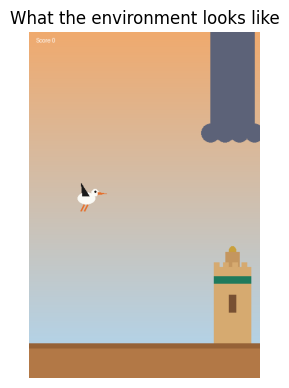

What the AI sees (5 numbers): [-0.04 -0.65  0.55 -0.02  0.3 ]


In [3]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from stork_env import StorkEnv

LEVELS = {"easy": 0.0, "medium": 0.5, "hard": 1.0}

# a quick look at the world
env = StorkEnv(difficulty=0.0, render_mode="rgb_array")
obs, _ = env.reset(seed=1)
for _ in range(40):
    obs, *_ = env.step(int(obs[3] < -0.09 and obs[1] > 0))
plt.figure(figsize=(3, 4.5)); plt.imshow(env.render()); plt.axis("off"); plt.title("What the environment looks like"); plt.show()
print("What the AI sees (5 numbers):", np.round(obs, 2))

Saving everything to Google Drive, so nothing is lost if Colab disconnects.

In [4]:
SAVE_DIR = "results"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/stork_flight"
except Exception as e:
    print("Not saving to Drive:", e)
os.makedirs(SAVE_DIR, exist_ok=True)
print("Saving to", SAVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving to /content/drive/MyDrive/stork_flight


## 2. Baselines: what does "good" look like?

Before training anything, two simple pilots set the bar:
- **Random:** flaps at random (8% of steps).
- **Simple rule:** written by me in one line: *flap when you're below the centre of the gap and falling.*

Every pilot is tested on the same 20 courses (seeds 500–519), so the comparison is fair.

In [ ]:
class RandomPilot:
    def __init__(self): self.rng = np.random.default_rng(0)
    def predict(self, obs, deterministic=True):
        return int(self.rng.random() < 0.08), None

class RulePilot:
    def predict(self, obs, deterministic=True):
        return int(obs[3] < -0.09 and obs[1] > 0), None

def measure(pilot, difficulty, n=20):
    """Fly n test courses. Returns the average and best number of minarets passed."""
    env = StorkEnv(difficulty=difficulty)
    scores, full = [], 0
    for ep in range(n):
        obs, _ = env.reset(seed=500 + ep)
        done = False
        while not done:
            a, _ = pilot.predict(obs, deterministic=True)
            obs, r, term, trunc, info = env.step(int(a))
            done = term or trunc
        scores.append(info["score"])
        full += trunc
    return {"avg minarets": round(float(np.mean(scores)), 1), "best": int(max(scores)),
            "survived 100s %": round(100 * full / n)}

rows = {}
for name, pilot in [("random", RandomPilot()), ("simple rule", RulePilot())]:
    for lvl, d in LEVELS.items():
        rows[(name, lvl)] = measure(pilot, d)
baseline = pd.DataFrame(rows).T
baseline.index.names = ["pilot", "level"]
baseline.to_csv(f"{SAVE_DIR}/baselines.csv")
baseline

avg minarets  best  survived 100s %
pilot       level                                      
random      easy             0.0   0.0              0.0
            medium           0.0   0.0              0.0
            hard             0.1   1.0              0.0
simple rule easy            41.0  41.0            100.0
            medium          43.0  49.0             80.0
            hard            26.9  56.0             25.0

## 3. My predictions

- On **easy**, I think the AI will score about 41 minarets on average, because it can learn from its mistakes.
- On **hard**, I think it will score about 45, because it should be lower than perfect due to the gaps being narrower and due to it being faster.
- Compared with the simple rule, I think the AI will be better because it can learn.
- An AI trained on **easy** and tested on **hard** will score about a bit worse (lower than the hard-trained AI's 45), because it has to adjust to faster speeds.

## 4. Training

One AI per difficulty, each trained for the same number of steps. Every finished flight is logged, so we can draw learning curves afterwards.

In [ ]:
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env

TIMESTEPS = 500_000   # per difficulty

models = {}
for lvl, d in LEVELS.items():
    print(f"Training on {lvl} ...")
    venv = make_vec_env(StorkEnv, n_envs=8, seed=0, env_kwargs={"difficulty": d},
                        monitor_dir=f"logs/{lvl}", monitor_kwargs={"info_keywords": ("score",)})
    model = PPO("MlpPolicy", venv, seed=0, verbose=0)
    model.learn(total_timesteps=TIMESTEPS, progress_bar=False)
    model.save(f"{SAVE_DIR}/stork_{lvl}")
    models[lvl] = model
    print(f"  done: {measure(model, d)}")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Training on easy ...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  done: {'avg minarets': 37.6, 'best': 41, 'survived 100s %': 90}
Training on medium ...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  done: {'avg minarets': 49.0, 'best': 49, 'survived 100s %': 100}
Training on hard ...
  done: {'avg minarets': 19.9, 'best': 56, 'survived 100s %': 15}


In [ ]:
# models = {lvl: PPO.load(f"{SAVE_DIR}/stork_{lvl}") for lvl in LEVELS}

## 5. Learning curves: how the AI improved during training

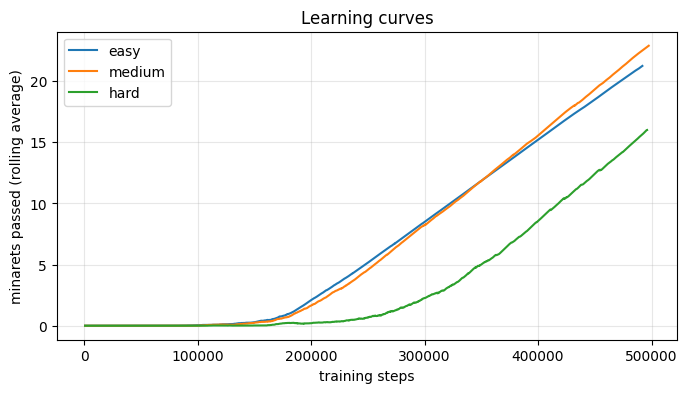

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
from stable_baselines3.common.monitor import load_results

fig, ax = plt.subplots(figsize=(8, 4))
for lvl in LEVELS:
    df = load_results(f"logs/{lvl}").sort_values("t")
    steps = df["l"].cumsum()
    ax.plot(steps, df["score"].rolling(200, min_periods=20).mean(), label=lvl)
ax.set_xlabel("training steps"); ax.set_ylabel("minarets passed (rolling average)")
ax.set_title("Learning curves"); ax.legend(); ax.grid(alpha=0.3)
plt.savefig(f"{SAVE_DIR}/learning_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Results

### 6a. The AI vs the baselines
Same 20 test courses as the baselines. The AI never saw these courses during training.

In [ ]:
rows = {}
for lvl, d in LEVELS.items():
    rows[("random", lvl)] = baseline.loc[("random", lvl)].to_dict()
    rows[("simple rule", lvl)] = baseline.loc[("simple rule", lvl)].to_dict()
    rows[("AI (PPO)", lvl)] = measure(models[lvl], d)
results = pd.DataFrame(rows).T
results.index.names = ["pilot", "level"]
results.to_csv(f"{SAVE_DIR}/results.csv")
results.unstack("pilot")["avg minarets"]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


pilot,AI (PPO),random,simple rule
level,,,
easy,37.6,0.0,41.0
hard,19.9,0.1,26.9
medium,49.0,0.0,43.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 6b. Does it generalise?
Each AI is tested on every difficulty. Rows: what it trained on. Columns: what it's tested on.

In [ ]:
grid = pd.DataFrame({test: {train: measure(models[train], d)["avg minarets"] for train in LEVELS}
                     for test, d in LEVELS.items()})
grid.index.name = "trained on"; grid.columns.name = "tested on"
grid.to_csv(f"{SAVE_DIR}/generalisation.csv")
grid

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


tested on,easy,medium,hard
trained on,,,
easy,37.6,13.1,1.4
medium,41.0,49.0,11.3
hard,36.9,44.1,19.9


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 6c. What I found

- I predicted the AI would beat my one-line rule on every level, but it only did on Medium (49.0 vs 43.0, a perfect score).
- On Easy it scored 37.6 against my prediction of 41, and on Hard it scored 19.9, far below my prediction of 45 and below my rule’s 26.9.
- My biggest miss was the last prediction: I expected the Easy-trained AI to do “a bit worse” on Hard, but it scored 1.4, almost as bad as random flapping.
- Skills transferred from harder levels to easier ones but not the other way round, and the Medium-trained AI was even perfect on Easy (41.0), beating the AI that trained on Easy


## 7. Export the AI for the browser game

The AI's brain is a small neural network: 5 inputs → 64 → 64 → 2 outputs (glide or flap). This saves its numbers as JSON, so the browser game can run it in JavaScript with no Python and no server.

In [ ]:
def export(model, path):
    p = model.policy
    layers = []
    for m in list(p.mlp_extractor.policy_net) + [p.action_net]:
        if hasattr(m, "weight"):
            layers.append({"W": np.round(m.weight.detach().cpu().numpy(), 5).tolist(),
                           "b": np.round(m.bias.detach().cpu().numpy(), 5).tolist()})
    out = {"activation": "tanh", "inputs": ["height", "vertical speed", "distance to next gap",
           "gap centre minus height", "gap size"], "actions": ["glide", "flap"], "layers": layers}
    with open(path, "w") as f: json.dump(out, f)
    return os.path.getsize(path) // 1024

for lvl in LEVELS:
    print(lvl, export(models[lvl], f"{SAVE_DIR}/stork_ai_{lvl}.json"), "KB")

# sanity check: the exported numbers give the same decisions as the real model
w = json.load(open(f"{SAVE_DIR}/stork_ai_easy.json"))
def act(obs):
    x = np.array(obs, dtype=np.float32)
    for i, L in enumerate(w["layers"]):
        x = np.array(L["W"]) @ x + np.array(L["b"])
        if i < len(w["layers"]) - 1: x = np.tanh(x)
    return int(np.argmax(x))
env = StorkEnv(0.0); obs, _ = env.reset(seed=7); same = 0
for _ in range(500):
    a, _ = models["easy"].predict(obs, deterministic=True); same += act(obs) == int(a)
    obs, r, term, trunc, _ = env.step(int(a))
    if term or trunc: obs, _ = env.reset()
print(f"exported AI agrees with the real model on {same}/500 decisions")

easy 97 KB
medium 97 KB
hard 97 KB
exported AI agrees with the real model on 500/500 decisions


Downloading the files:

In [ ]:
try:
    from google.colab import files
    for lvl in LEVELS: files.download(f"{SAVE_DIR}/stork_ai_{lvl}.json")
    for name in ["results.csv", "generalisation.csv", "learning_curves.png"]: files.download(f"{SAVE_DIR}/{name}")
except Exception as e:
    print("Download them from the Files panel on the left:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. More practice, and opponents for the game

Two things made me come back to this. First, the learning curves in section 5 were still going up when training stopped at 500k steps, so the AIs probably weren't finished learning. Second, after I put the AIs into the browser game, racing them felt impossible on Easy and Medium, and "Hard" was the easiest race to win because the Hard AI is the weakest.

So this time I train each level for 1 million steps and save a snapshot every 100k. Testing every snapshot on the same 20 courses shows how skill grows with practice. The snapshots also become the opponents in the game, from Beginner to Seasoned, so every opponent is a real AI at a real point in its training, not one I made worse on purpose.

In [5]:
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.callbacks import CheckpointCallback

TOTAL, SNAP = 1_000_000, 100_000

for lvl, d in LEVELS.items():
    print(f"Training {lvl} for {TOTAL:,} steps ...")
    venv = make_vec_env(StorkEnv, n_envs=8, seed=0, env_kwargs={"difficulty": d})
    model = PPO("MlpPolicy", venv, seed=0, verbose=0)
    snapshots = CheckpointCallback(save_freq=SNAP // 8, save_path=f"{SAVE_DIR}/snapshots/{lvl}", name_prefix="stork")
    model.learn(total_timesteps=TOTAL, callback=snapshots)
print("done")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Training easy for 1,000,000 steps ...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Training medium for 1,000,000 steps ...
Training hard for 1,000,000 steps ...
done


Testing every snapshot. `model.predict` is slow for this many runs, so I run the network myself with numpy (the same maths as the export in section 7).

easy tested
medium tested
hard tested


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


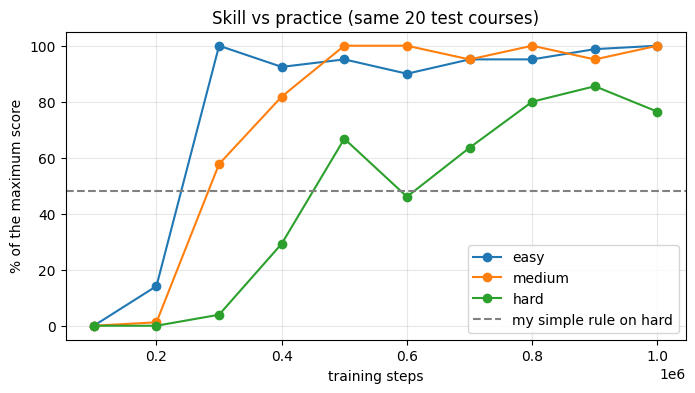

,easy,medium,hard
training steps,,,
100000,0.0,0.0,0.0
200000,5.8,0.6,0.0
300000,41.0,28.3,2.2
400000,37.9,40.1,16.4
500000,39.0,49.0,37.4
600000,36.9,49.0,25.8
700000,39.0,46.6,35.6
800000,39.0,49.0,44.8
900000,40.5,46.6,47.9


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [6]:
# Test every snapshot. The network is run with numpy (much faster than model.predict).
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
def layers_of(model):
    p = model.policy
    mods = [m for m in list(p.mlp_extractor.policy_net) + [p.action_net] if hasattr(m, "weight")]
    return [(m.weight.detach().cpu().numpy(), m.bias.detach().cpu().numpy()) for m in mods]

def fast_measure(layers, difficulty, n=20):
    env = StorkEnv(difficulty=difficulty)
    scores = []
    for ep in range(n):
        obs, _ = env.reset(seed=500 + ep)
        done = False
        while not done:
            x = obs
            for i, (Wm, bv) in enumerate(layers):
                x = Wm @ x + bv
                if i < len(layers) - 1: x = np.tanh(x)
            obs, r, term, trunc, info = env.step(int(np.argmax(x)))
            done = term or trunc
        scores.append(info["score"])
    return round(float(np.mean(scores)), 1)

nets, skill = {}, {}
for lvl, d in LEVELS.items():
    for steps in range(SNAP, TOTAL + 1, SNAP):
        nets[(lvl, steps)] = layers_of(PPO.load(f"{SAVE_DIR}/snapshots/{lvl}/stork_{steps}_steps"))
        skill[(lvl, steps)] = fast_measure(nets[(lvl, steps)], d)
    print(lvl, "tested")

practice = pd.Series(skill).unstack(0)[list(LEVELS)]
practice.index.name = "training steps"
practice.to_csv(f"{SAVE_DIR}/practice.csv")

MAX = {"easy": 41, "medium": 49, "hard": 56}          # most minarets possible in 100 seconds
fig, ax = plt.subplots(figsize=(8, 4))
for lvl in LEVELS:
    ax.plot(practice.index, practice[lvl] / MAX[lvl] * 100, marker="o", label=lvl)
ax.axhline(26.9 / 56 * 100, ls="--", color="gray", label="my simple rule on hard")
ax.set_xlabel("training steps"); ax.set_ylabel("% of the maximum score")
ax.set_title("Skill vs practice (same 20 test courses)"); ax.legend(); ax.grid(alpha=0.3)
plt.savefig(f"{SAVE_DIR}/practice.png", dpi=150, bbox_inches="tight"); plt.show()
practice

### Choosing the opponents
I pick opponents by how well they fly, not by a fixed number of steps. Easy and Medium go from almost 0% to almost 100% between 200k and 300k steps, so snapshots every 100k miss the in-between AIs. For those two levels I trained again up to 400k steps and saved a snapshot every 20k. Then, for each level, Seasoned is the best snapshot, and Beginner, Intermediate and Experienced are the snapshots closest to 25%, 55% and 85% of the maximum score.

In [7]:
# Easy and Medium jump from ~0% to ~100% between 200k and 300k steps,
# so I save a snapshot every 20k steps there to catch the in-between AIs.
FINE = 20_000
for lvl in ["easy", "medium"]:
    if os.path.exists(f"{SAVE_DIR}/fine/{lvl}/stork_400000_steps.zip"):
        print(lvl, "already done"); continue
    print("Fine snapshots for", lvl, "...")
    venv = make_vec_env(StorkEnv, n_envs=8, seed=0, env_kwargs={"difficulty": LEVELS[lvl]})
    model = PPO("MlpPolicy", venv, seed=0, verbose=0)
    model.learn(total_timesteps=400_000,
                callback=CheckpointCallback(save_freq=FINE // 8, save_path=f"{SAVE_DIR}/fine/{lvl}", name_prefix="stork"))
print("done")

Fine snapshots for easy ...
Fine snapshots for medium ...
done


In [8]:
# All snapshots for each level, with their test scores
pool = {lvl: {("main", st): (nets[(lvl, st)], float(practice.loc[st, lvl])) for st in practice.index} for lvl in LEVELS}
for lvl in ["easy", "medium"]:
    for st in range(FINE, 400_001, FINE):
        layers = layers_of(PPO.load(f"{SAVE_DIR}/fine/{lvl}/stork_{st}_steps"))
        pool[lvl][("fine", st)] = (layers, fast_measure(layers, LEVELS[lvl]))

# Seasoned = the best snapshot; the others = the snapshot closest to a target skill level
TARGETS = {"Beginner": 0.25, "Intermediate": 0.55, "Experienced": 0.85}
tiers, rows = {}, []
for lvl in LEVELS:
    cands = pool[lvl]
    best = max(cands, key=lambda k: (cands[k][1], k[0] == "main", k[1]))
    chosen, used = {"Seasoned": best}, {best}
    for name, share in TARGETS.items():
        k = min((k for k in cands if k not in used), key=lambda k: abs(cands[k][1] - share * MAX[lvl]))
        chosen[name] = k; used.add(k)
    tiers[lvl] = {}
    for name in ["Beginner", "Intermediate", "Experienced", "Seasoned"]:
        run, steps = chosen[name]; layers, score = cands[chosen[name]]
        tiers[lvl][name] = {"run": run, "steps": steps, "score": score,
                            "layers": [{"W": np.round(Wm, 5).tolist(), "b": np.round(bv, 5).tolist()} for Wm, bv in layers]}
        rows.append({"level": lvl, "opponent": name, "steps": f"{steps:,} ({run})", "avg minarets": score})

with open(f"{SAVE_DIR}/stork_ai_opponents.json", "w") as f: json.dump(tiers, f)
try:
    from google.colab import files
    files.download(f"{SAVE_DIR}/stork_ai_opponents.json")
except Exception as e:
    print("Download from the Files panel:", e)
table = pd.DataFrame(rows).pivot(index="opponent", columns="level", values="avg minarets")
table.loc[["Beginner", "Intermediate", "Experienced", "Seasoned"], list(LEVELS)]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


level,easy,medium,hard
opponent,,,
Beginner,13.8,11.1,16.4
Intermediate,20.6,28.3,35.6
Experienced,36.9,40.1,44.8
Seasoned,41.0,49.0,47.9


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 8b. What I found

- **More practice let the Hard AI beat my rule.** At 500k steps it scored 37.4, already above my rule's 26.9. It peaked at 47.9 after 900k steps and ended at 42.8 at 1 million.
- **One training run can be misleading.** In section 4, the Hard AI scored 19.9 after 500k steps. In this run, with the same settings, it scored 37.4 at the same point. So my earlier conclusion that "the Hard AI is weak" was partly the luck of that first run.
- **More practice isn't always better.** Easy was perfect (41.0) at 300k steps, dropped to between 36.9 and 39.0, and only came back to 41.0 at 1 million. Hard dipped at 600k (25.8) and again at the end.
- **Easy and Medium learn very suddenly.** Both go from almost nothing at 200k steps to near the maximum by 300k–500k, which is why I needed extra snapshots every 20k steps to find in-between opponents for the game.
- **What surprised me most:** how unpredictable training was. The same code gave very different results from one run to the next, and sometimes the AI got *worse* with more practice, when I expected practice to only make it better.

## Notes
- **Physics:** 30 steps per second, gravity 0.5 per step, flap speed −8. The gap is 180 − 50 × difficulty pixels and the speed is 3 + difficulty pixels per step. These are the same numbers as the browser game (`game.js`).
- **Fairness:** every pilot is tested on the same 20 courses (seeds 500–519), and the AIs never trained on them.
- **Limits:** one training seed per difficulty. A stronger test would repeat training with 3 seeds, as I did in Part 1.
- **AI use:** I wrote this project with help from an AI coding assistant. The questions, the predictions and the conclusions are mine.